# Sri Lanka Tourist Arrivals — Exploratory Data Analysis

**Target unit:** Arrivals are tourists per country-month. Aggregate totals are labelled as tourists or thousands of tourists.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import seasonal_decompose
sns.set_theme(style='whitegrid')
out=Path('../artifacts/eda'); out.mkdir(parents=True,exist_ok=True)
df=pd.read_csv('../data/processed/cleaned_country_month.csv',parse_dates=['Date']).sort_values(['Date','Country'])
monthly=df.groupby('Date')['Arrivals'].sum().asfreq('MS')
print(df.shape,df['Date'].min(),df['Date'].max(),df['Country'].nunique())

Matplotlib is building the font cache; this may take a moment.


(21518, 3) 2018-01-01 00:00:00 2026-10-01 00:00:00 203


## 1. Dataset Overview and Cleaning Summary

In [2]:
overview=pd.DataFrame({'Metric':['Rows','Countries','Monthly periods','Date range','Missing values','Zero rows','Negative rows'],'Value':[len(df),df['Country'].nunique(),df['Date'].nunique(),f"{df['Date'].min():%Y-%m-%d} to {df['Date'].max():%Y-%m-%d}",int(df.isna().sum().sum()),int((df['Arrivals']==0).sum()),int((df['Arrivals']<0).sum())]})
overview

,Metric,Value
0,Rows,21518
1,Countries,203
2,Monthly periods,106
3,Date range,2018-01-01 to 2026-10-01
4,Missing values,0
5,Zero rows,6835
6,Negative rows,0


## 2. Total Monthly Arrivals Over Time

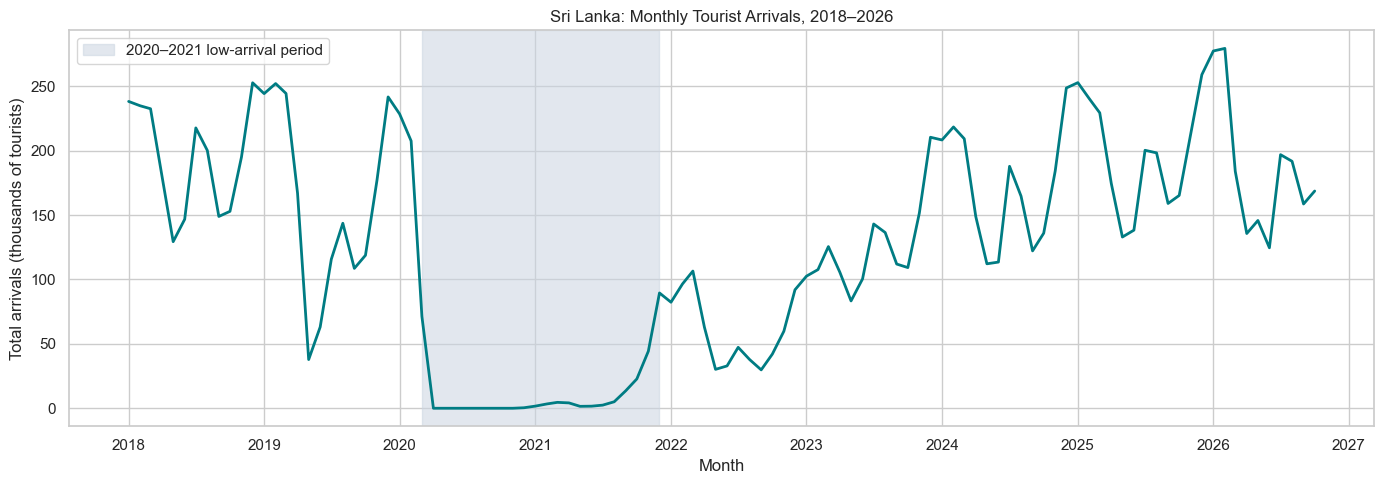

In [3]:
fig,ax=plt.subplots(figsize=(14,5)); ax.plot(monthly.index,monthly.values/1000,color='#007C83',linewidth=2); ax.set(title='Sri Lanka: Monthly Tourist Arrivals, 2018–2026',xlabel='Month',ylabel='Total arrivals (thousands of tourists)'); ax.axvspan(pd.Timestamp('2020-03-01'),pd.Timestamp('2021-12-01'),color='#CBD5E1',alpha=.55,label='2020–2021 low-arrival period'); ax.legend(); fig.tight_layout(); fig.savefig(out/'monthly_totals.png',dpi=150); plt.show()

## 3. Annual Totals and Year-over-Year Change

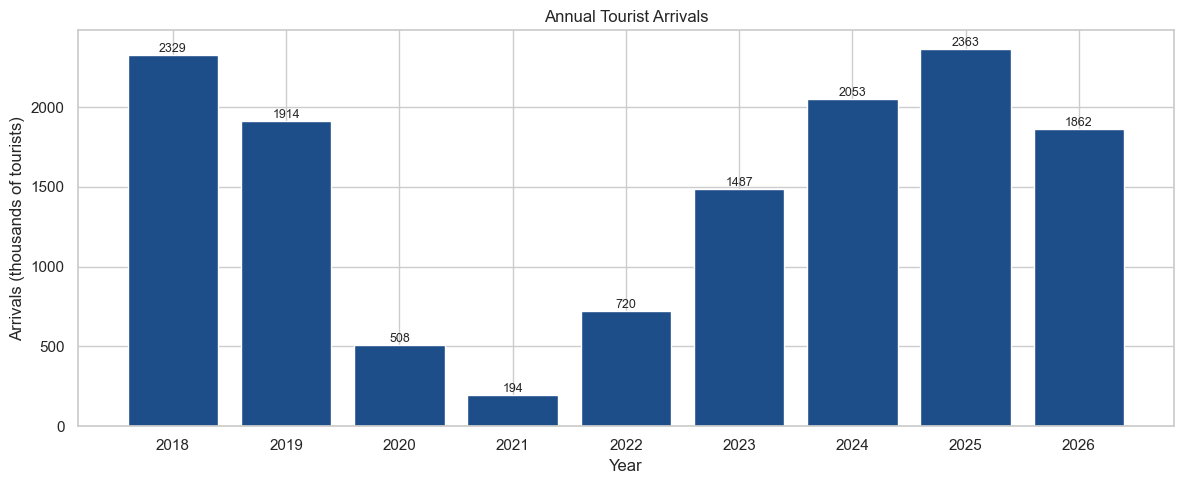

      Annual arrivals  YoY change (%)
Date                                 
2018          2328502             NaN
2019          1913689           -17.8
2020           507669           -73.5
2021           194488           -61.7
2022           719937           270.2
2023          1487295           106.6
2024          2053450            38.1
2025          2362509            15.1
2026          1862294           -21.2


In [4]:
annual=df.groupby(df['Date'].dt.year)['Arrivals'].sum(); yoy=annual.pct_change()*100
fig,ax=plt.subplots(figsize=(12,5)); ax.bar(annual.index.astype(str),annual.values/1000,color='#1D4E89'); ax.set(title='Annual Tourist Arrivals',xlabel='Year',ylabel='Arrivals (thousands of tourists)')
for i,(yr,val) in enumerate(annual.items()): ax.text(i,val/1000,f'{val/1000:.0f}',ha='center',va='bottom',fontsize=9)
fig.tight_layout(); fig.savefig(out/'annual_totals.png',dpi=150); plt.show()
print(pd.DataFrame({'Annual arrivals':annual,'YoY change (%)':yoy.round(1)}))

## 4. Seasonality: Month of Year and Heatmap

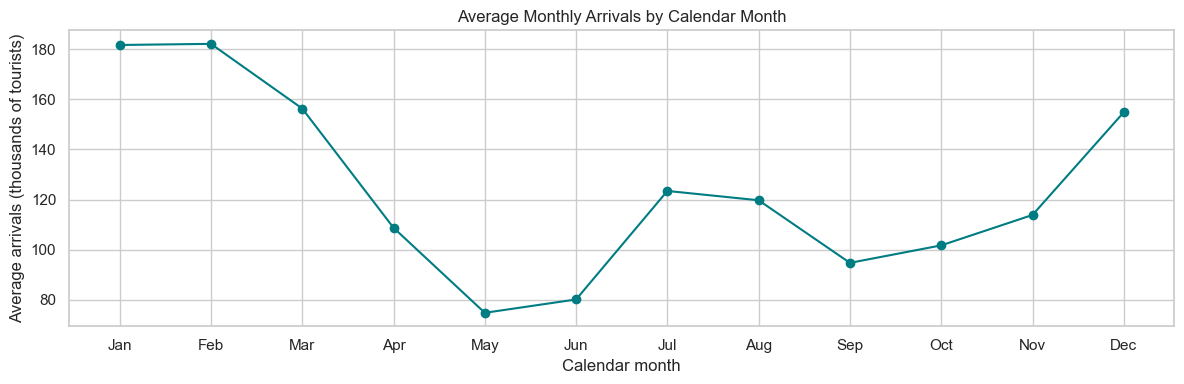

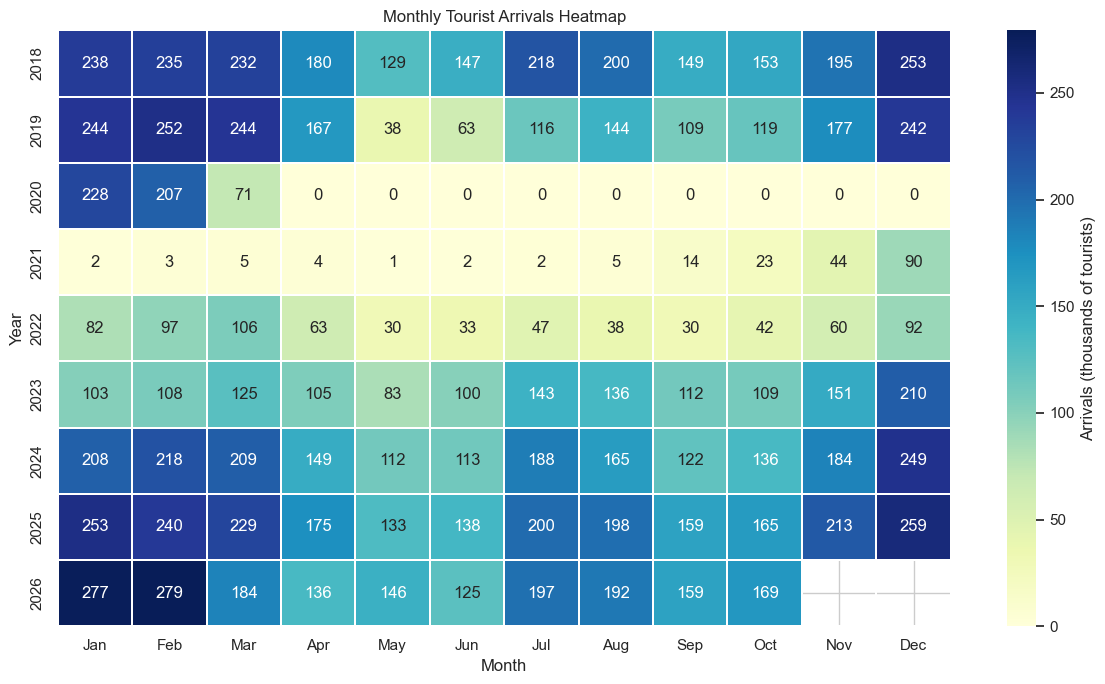

In [5]:
month_avg=df.groupby(df['Date'].dt.month)['Arrivals'].sum()/df['Date'].dt.year.nunique(); month_names=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
fig,ax=plt.subplots(figsize=(12,4)); ax.plot(range(1,13),month_avg.values/1000,marker='o',color='#007C83'); ax.set_xticks(range(1,13),month_names); ax.set(title='Average Monthly Arrivals by Calendar Month',xlabel='Calendar month',ylabel='Average arrivals (thousands of tourists)'); fig.tight_layout(); fig.savefig(out/'seasonal_month_average.png',dpi=150); plt.show()
heat=df.assign(Year=df['Date'].dt.year,Month=df['Date'].dt.month).pivot_table(index='Year',columns='Month',values='Arrivals',aggfunc='sum')/1000
fig,ax=plt.subplots(figsize=(12,7)); sns.heatmap(heat,cmap='YlGnBu',annot=True,fmt='.0f',linewidths=.3,ax=ax,cbar_kws={'label':'Arrivals (thousands of tourists)'}); ax.set(title='Monthly Tourist Arrivals Heatmap',xlabel='Month',ylabel='Year'); ax.set_xticklabels(month_names); fig.tight_layout(); fig.savefig(out/'seasonal_heatmap.png',dpi=150); plt.show()

## 5. Top 10 Source Countries

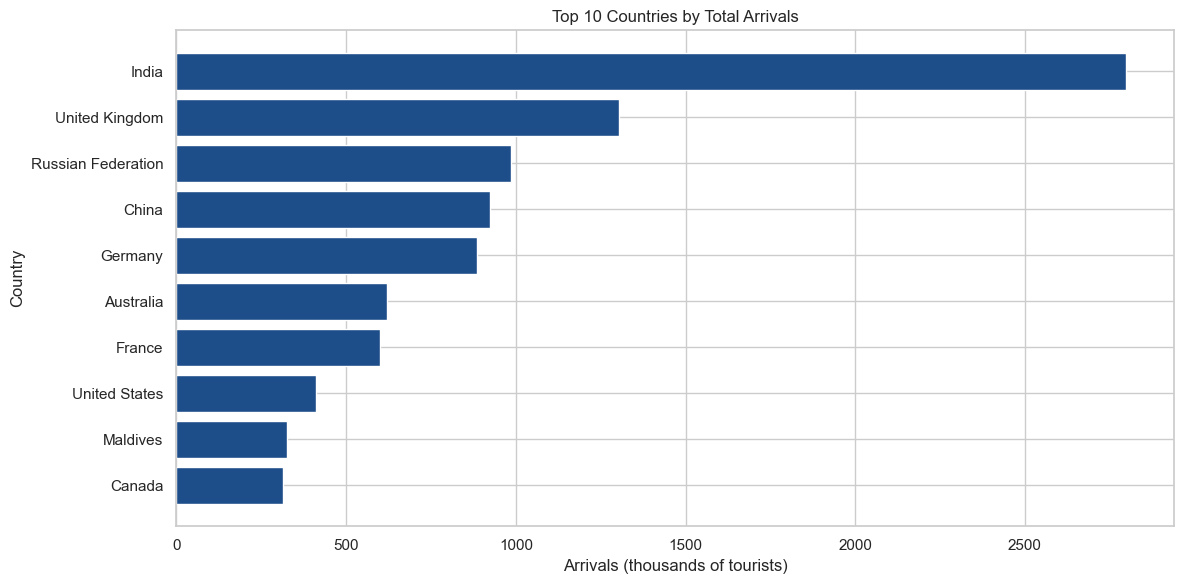

                    Arrivals  Share of top-10 total (%)
Country                                                
India                2799472                      30.53
United Kingdom       1304073                      14.22
Russian Federation    984348                      10.73
China                 923352                      10.07
Germany               886172                       9.66
Australia             621224                       6.77
France                598910                       6.53
United States         410620                       4.48
Maldives              326822                       3.56
Canada                314676                       3.43


In [6]:
totals=df.groupby('Country')['Arrivals'].sum().sort_values(ascending=False); top10=totals.head(10); share=top10/totals.head(10).sum()*100
fig,ax=plt.subplots(figsize=(12,6)); ax.barh(top10.index[::-1],top10.values[::-1]/1000,color='#1D4E89'); ax.set(title='Top 10 Countries by Total Arrivals',xlabel='Arrivals (thousands of tourists)',ylabel='Country'); fig.tight_layout(); fig.savefig(out/'top10_countries.png',dpi=150); plt.show()
print(pd.DataFrame({'Arrivals':top10,'Share of top-10 total (%)':share.round(2)}))

## 6. Monthly Trends for Top Source Countries

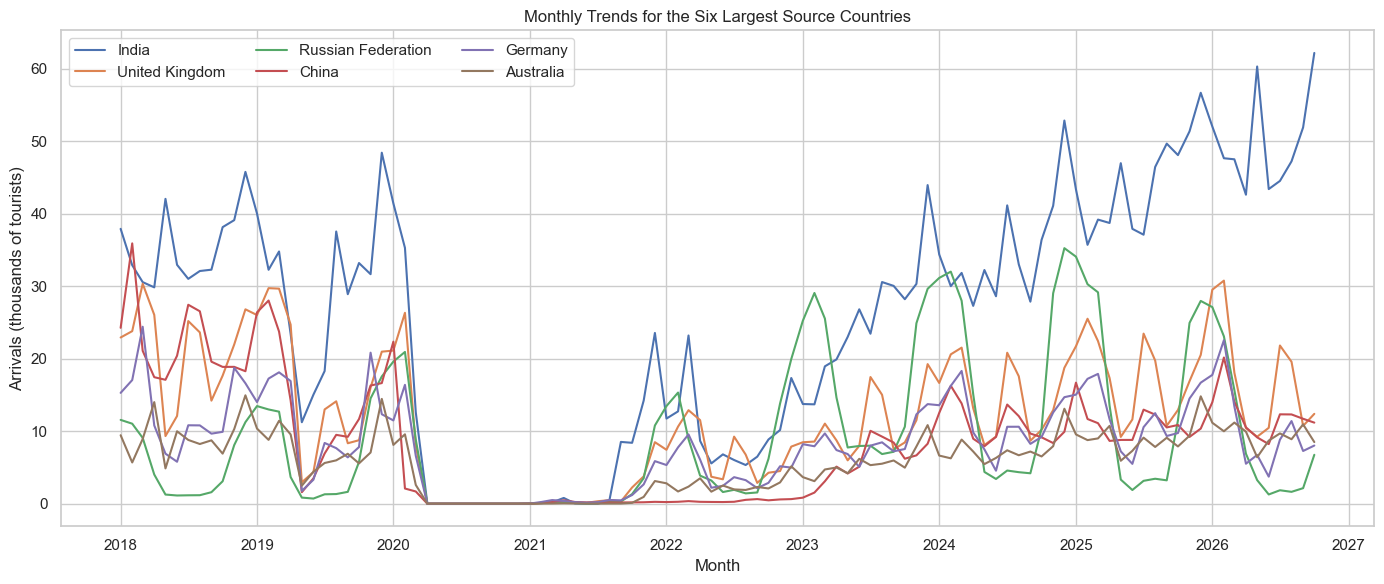

In [7]:
selected=totals.head(6).index; fig,ax=plt.subplots(figsize=(14,6))
for country in selected:
 s=df[df['Country']==country].set_index('Date')['Arrivals']/1000; ax.plot(s.index,s.values,label=country)
ax.set(title='Monthly Trends for the Six Largest Source Countries',xlabel='Month',ylabel='Arrivals (thousands of tourists)'); ax.legend(ncol=3); fig.tight_layout(); fig.savefig(out/'top_country_trends.png',dpi=150); plt.show()

## 7. Distribution and Zeros

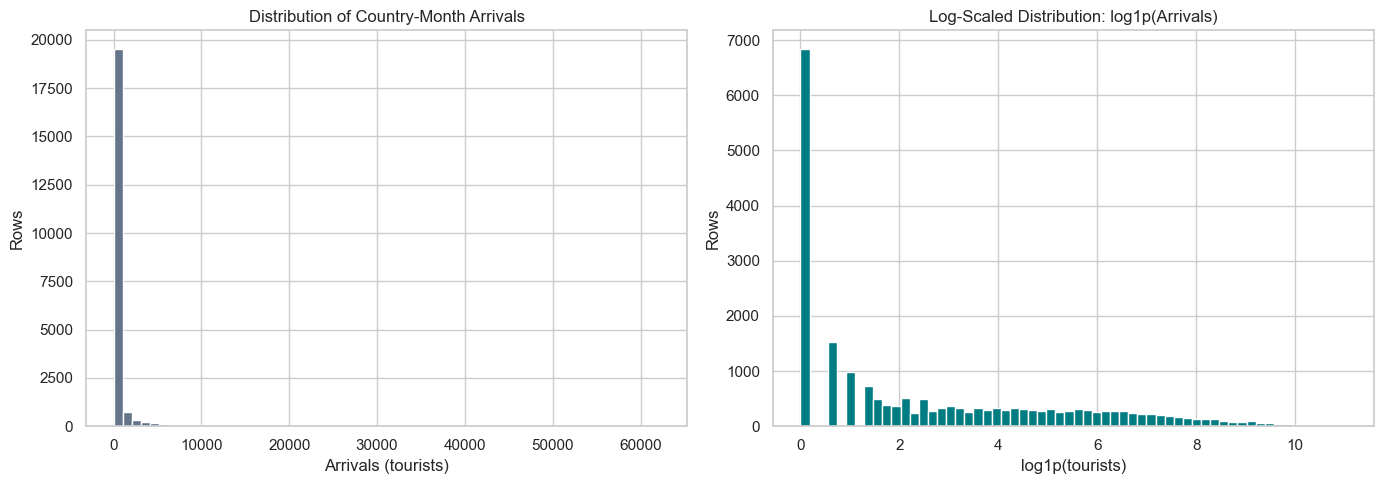

Zero rows: 6835 of 21518 (31.8%)


In [8]:
fig,axes=plt.subplots(1,2,figsize=(14,5)); axes[0].hist(df['Arrivals'],bins=60,color='#64748B',edgecolor='white'); axes[0].set(title='Distribution of Country-Month Arrivals',xlabel='Arrivals (tourists)',ylabel='Rows'); axes[1].hist(np.log1p(df['Arrivals']),bins=60,color='#007C83',edgecolor='white'); axes[1].set(title='Log-Scaled Distribution: log1p(Arrivals)',xlabel='log1p(tourists)',ylabel='Rows'); fig.tight_layout(); fig.savefig(out/'arrival_distribution.png',dpi=150); plt.show()
print('Zero rows:',int((df['Arrivals']==0).sum()),'of',len(df),f"({(df['Arrivals']==0).mean()*100:.1f}%)")

### Sparse countries
A country is flagged sparse if 50% or more of its country-month observations are zero.

In [9]:
country_zero=df.assign(IsZero=df['Arrivals']==0).groupby('Country')['IsZero'].mean(); sparse=country_zero[country_zero>=.5].sort_values(ascending=False); print('Sparse countries:',len(sparse)); print(sparse.head(20).to_string())

Sparse countries: 48
Country
Saint Barthelemy            0.990566
Guam                        0.990566
Isle Of Man                 0.990566
Aruba                       0.981132
Vatican City                0.981132
Sao Tome And Principe       0.971698
Netherlands Antilles        0.971698
Korea                       0.962264
Guinea                      0.952830
Equatorial Guinea           0.924528
Nauru                       0.915094
Tuvalu                      0.915094
Palau                       0.896226
Kiribati                    0.886792
Micronesia                  0.886792
Central African Republic    0.886792
Republic Of Congo           0.877358
Marshall Islands            0.858491
Hong Kong                   0.839623
Guinea-Bissau               0.830189


## 8. Impact Periods

The chart describes observed data. External explanations require cited context and are not inferred alone.

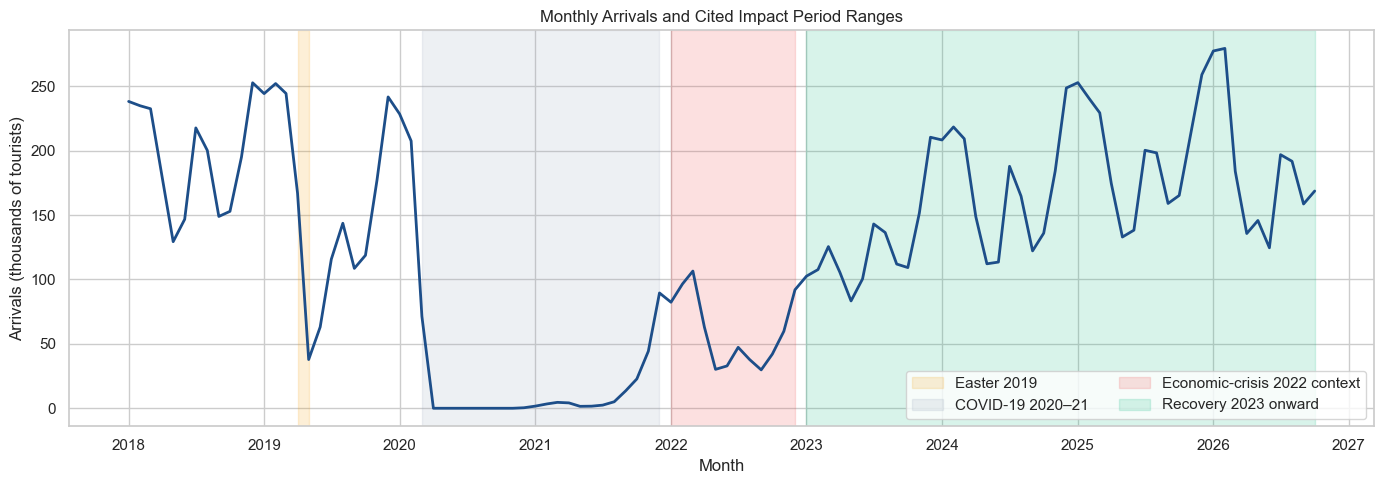

In [10]:
fig,ax=plt.subplots(figsize=(14,5)); ax.plot(monthly.index,monthly.values/1000,color='#1D4E89',linewidth=2); periods=[('Easter 2019',pd.Timestamp('2019-04-01'),pd.Timestamp('2019-05-01'),'#F59E0B'),('COVID-19 2020–21',pd.Timestamp('2020-03-01'),pd.Timestamp('2021-12-01'),'#94A3B8'),('Economic-crisis 2022 context',pd.Timestamp('2022-01-01'),pd.Timestamp('2022-12-01'),'#EF4444'),('Recovery 2023 onward',pd.Timestamp('2023-01-01'),monthly.index.max(),'#10B981')]
for name,start,end,color in periods: ax.axvspan(start,end,color=color,alpha=.16,label=name)
ax.set(title='Monthly Arrivals and Cited Impact Period Ranges',xlabel='Month',ylabel='Arrivals (thousands of tourists)'); ax.legend(ncol=2); fig.tight_layout(); fig.savefig(out/'impact_periods.png',dpi=150); plt.show()

## 9. Country Growth and Decline Rankings

In [11]:
pivot=df.pivot(index='Country',columns='Date',values='Arrivals')
def for_year(year): return pivot.loc[:,pivot.columns[pivot.columns.year==year]].sum(axis=1)
compare=pd.DataFrame({'2019':for_year(2019),'2025':for_year(2025)}); compare['Absolute change']=compare['2025']-compare['2019']; compare['Percent change']=compare['2025'].div(compare['2019'].where(compare['2019']>0)).sub(1).mul(100)
print('Largest absolute growth'); print(compare.sort_values('Absolute change',ascending=False).head(10).round(1).to_string()); print('Largest absolute decline'); print(compare.sort_values('Absolute change').head(10).round(1).to_string())

Largest absolute growth
                      2019    2025  Absolute change  Percent change
Country                                                            
India               355002  531511           176509            49.7
Russian Federation   86549  186580           100031           115.6
Bangladesh            8261   59563            51302           621.0
Poland               20896   49989            29093           139.2
Netherlands          38993   64164            25171            64.6
Spain                24489   46038            21549            88.0
France               87623  109041            21418            24.4
Australia            92674  109487            16813            18.1
Italy                36147   50430            14283            39.5
United Kingdom      198776  212277            13501             6.8
Largest absolute decline
                 2019    2025  Absolute change  Percent change
Country                                                       
China    

## 10. ACF and Seasonal Decomposition

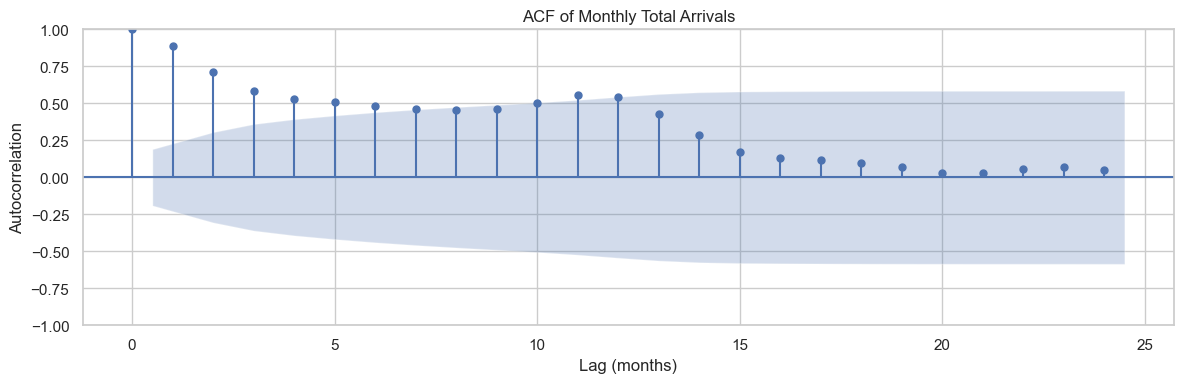

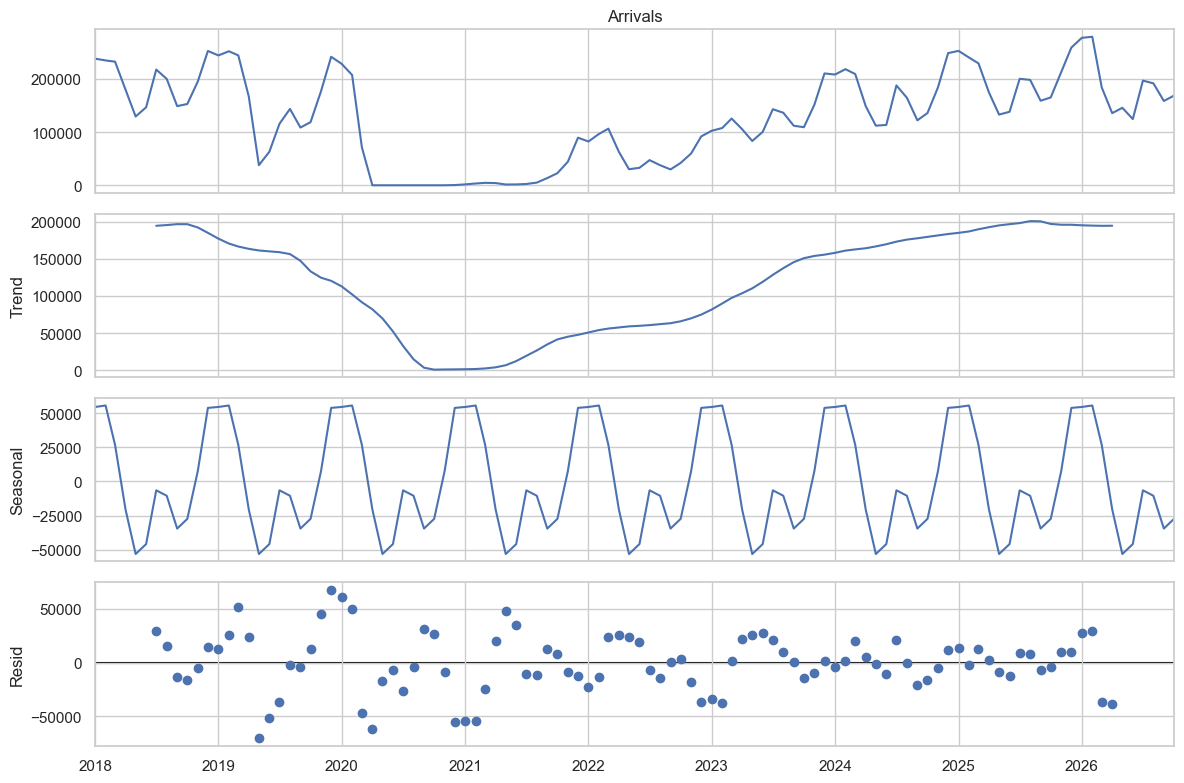

In [12]:
fig=plt.figure(figsize=(12,4)); plot_acf(monthly.dropna(),lags=24,ax=plt.gca()); plt.title('ACF of Monthly Total Arrivals'); plt.xlabel('Lag (months)'); plt.ylabel('Autocorrelation'); fig.tight_layout(); fig.savefig(out/'acf_total.png',dpi=150); plt.show()
decomp=seasonal_decompose(monthly,model='additive',period=12); fig=decomp.plot(); fig.set_size_inches(12,8); fig.tight_layout(); fig.savefig(out/'decomposition_total.png',dpi=150); plt.show()
for country in totals.head(3).index:
 s=df[df['Country']==country].set_index('Date')['Arrivals'].asfreq('MS')
 if s.notna().sum()<24: continue
 d=seasonal_decompose(s,model='additive',period=12,extrapolate_trend='freq'); fig=d.plot(); fig.set_size_inches(12,8); fig.suptitle('Seasonal Decomposition — '+country,y=1.01); fig.tight_layout(); slug='_'.join(country.lower().split()); fig.savefig(out/('decomposition_'+slug+'.png'),dpi=150); plt.close(fig)

## 11. Outlier Analysis

IQR upper threshold: 272 tourists; outlier country-month rows: 3964
      Date Country  Arrivals
2026-10-01   India     62211
2026-05-01   India     60342
2025-12-01   India     56715
2024-12-01   India     52881
2026-01-01   India     52061
2026-09-01   India     51931
2025-11-01   India     51391
2025-09-01   India     49697
2019-12-01   India     48442
2025-10-01   India     48113
2026-02-01   India     47679
2026-03-01   India     47533
2026-08-01   India     47253
2025-05-01   India     47001
2025-08-01   India     46473
2018-12-01   India     45797
2026-07-01   India     44547
2023-12-01   India     43973
2026-06-01   India     43423
2025-01-01   India     43375


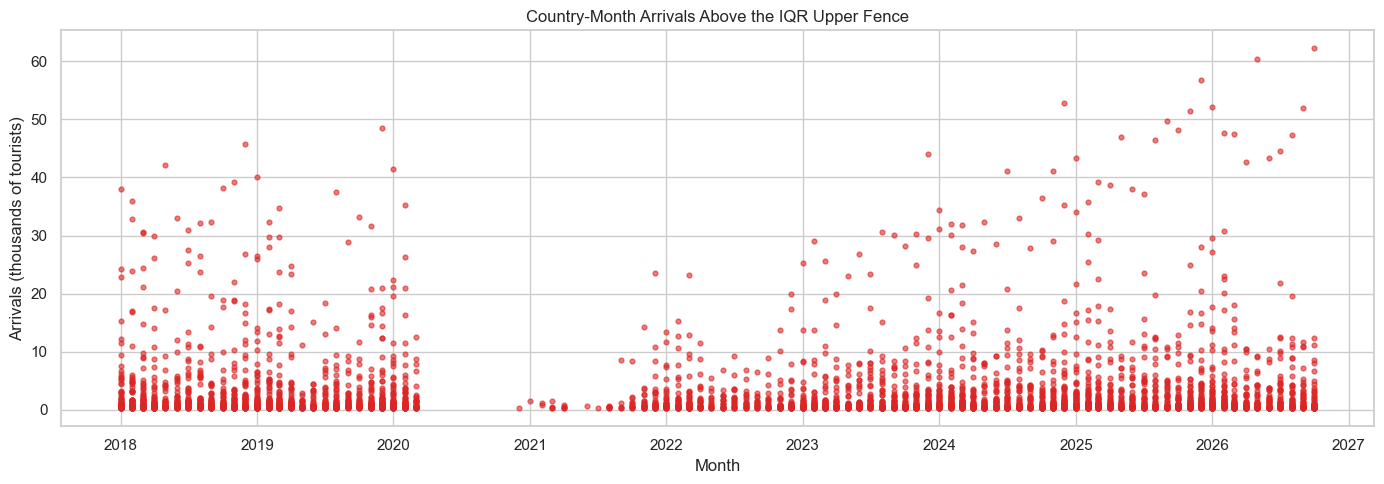

In [13]:
q1,q3=df['Arrivals'].quantile([.25,.75]); iqr=q3-q1; upper=q3+1.5*iqr; outliers=df[df['Arrivals']>upper].sort_values('Arrivals',ascending=False)
print(f'IQR upper threshold: {upper:.0f} tourists; outlier country-month rows: {len(outliers)}'); print(outliers.head(20).to_string(index=False))
fig,ax=plt.subplots(figsize=(14,5)); ax.scatter(outliers['Date'],outliers['Arrivals']/1000,s=12,alpha=.6,color='#DC2626'); ax.set(title='Country-Month Arrivals Above the IQR Upper Fence',xlabel='Month',ylabel='Arrivals (thousands of tourists)'); fig.tight_layout(); fig.savefig(out/'outliers.png',dpi=150); plt.show()

## 12. Verified vs Unresolved Source Context

- SLTDA 2020 monthly table gives 2019 annual 1,913,702 and 2020 total 507,704.
- 2019 May and 2026 October match spot checks exactly.
- 2019 annual differs by 12 tourists; 2026 January and February differ by 2 and 1 tourists.
- Kaggle API metadata reports MIT licence; it does not replace SLTDA verification.

Sources: [SLTDA 2020](https://www.sltda.gov.lk/en/monthly-tourist-arrivals-reports-2020), [SLTDA 2026](https://www.sltda.gov.lk/en/monthly-tourist-arrivals-reports-2026), [Kaggle dataset](https://www.kaggle.com/datasets/amandapriyashantha/sri-lanka-tourists-arrival).

## My interpretation — complete after execution

Use the actual printed tables and charts before recording conclusions. In the viva, distinguish observed patterns, cleaning assumptions, and external context.